In [46]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import os
from matplotlib.ticker import MultipleLocator
from scipy.optimize import curve_fit
import matplotlib.ticker as ticker
from pathlib import Path




[0.      0.1111  0.1333  0.1556  0.1778  0.2     0.02222 0.04444 0.06667
 0.08889]
10


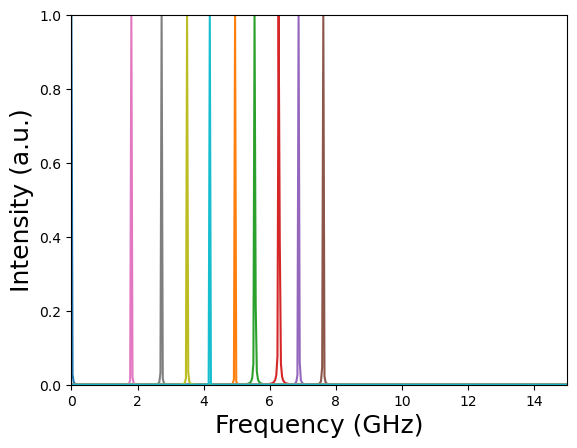

In [56]:
'''This code block loops over time-domain data generated by the previous block to
to extract the resonant frequency at each field. Note that the resonance frequency
is simply taken to be the maximum-intensity frequency bin, which may not be a suitable
method for all spectra.'''


# Folder containing the data tables
# folder = 'C:/Users/nicoe/OneDrive - Imperial College London/Documents/A Univeristy/Year 4/Masters Project/Results/Experiments/Simulations/mumax/Mumax_20260330_1835/Experimental Kittel Mode Field Dependence'
folder = "C:\\Users\\nicoe\\OneDrive - Imperial College London\\Documents\\A Univeristy\\Year 4\\Masters Project\\Results\\Experiments\\Simulations\\mumax\\YIG_simulations\\Mumax_20260513_0140\\YIG_simulation_results"
# folder = "C:\\Users\\nicoe\\OneDrive - Imperial College London\\Documents\\A Univeristy\\Year 4\\Masters Project\\Results\\Experiments\\Simulations\\mumax\\Py_simulations\\Py_out\\Mumax_20260512_2215\\Py_simulation_results"


# Initialise empty lists to store fields and corresponding resonance frequencies
fields = []
resFreqs = []

frequencies = []

intensities = []

# Loop over each file in the folder that matches the pattern 'table<field>.txt'
for filename in os.listdir(folder):
    if filename.startswith('table') and filename.endswith('.txt'):
        field_str = filename[5:-4]  # Extract the field value from the filename
        try:
            field = float(field_str)  # Convert the field value to a float
        except ValueError:
            continue  # If the field cannot be converted to a float, skip the file

        # Load data from the current table
        data = np.loadtxt(os.path.join(folder, filename), skiprows=1)
        times = np.array([d[0] for d in data])
        times = times - times[0]  # Set the first time step to t = 0.
        mx = np.array([d[1] for d in data])
        my = np.array([d[2] for d in data])
        mz = np.array([d[3] for d in data])
        Bz = np.array([d[7] for d in data])

        # Fourier transform the z-component of the magnetisation
        spectrum = np.fft.fftshift(np.fft.fft(mz))
        intensity = np.abs(spectrum)**2
        timeStep = times[1] - times[0]
        freqs = np.fft.fftshift(np.fft.fftfreq(len(times), timeStep))  # Frequency bins for the FFT
        resFreq = np.abs(freqs[np.argmax(intensity)])  # Resonance frequency from the spectrum

        # Store the field and corresponding resonance frequency
        fields.append(field)
        resFreqs.append(resFreq)

        # Plot the Fourier intensity as a function of frequency (uncomment to generate individual spectra for each field)
        plt.plot(freqs / 1e9, intensity / intensity.max())
        plt.xlim(0, 15)
        plt.ylim(0, 1)
        plt.xlabel('Frequency (GHz)', size=18)
        plt.ylabel('Intensity (a.u.)', size=18)
        # plt.savefig('spectrum_'+field_str+'.png')

        # print(f'Resonance frequency for {field*1e3} mT = {resFreq / 1e9} GHz')

        frequencies.append(freqs)
        intensities.append(intensity)



# Convert fields and resFreqs to numpy arrays
fields = np.array(fields)
resFreqs = np.array(resFreqs)

print(fields)
print(len(fields))
# print(frequencies)



In [54]:
def kittel_fit():
        """
        Fits the Kittel formula to the extracted resonance frequencies to get M_eff and gamma.
        """


        def kittel(B, gamma_over_2pi, M_eff):
            '''Kittel formula for in-plane magnetisation'''

            mu_0 = 1.2566e-6     # N/A^2

            return (gamma_over_2pi)*np.sqrt(B*(B + mu_0*M_eff))

        B = fields
        F = resFreqs

        popt, pcov = curve_fit(kittel, B, F, p0=[28e9, 200e3])

        perr = np.sqrt(np.diag(pcov))

        print(f"Fitted gamma: {popt[0]/1e9:.4f} ± {perr[0]/1e9:.4f} GHz/T")
        print(f"Fitted M_eff: {popt[1]/1e3:.4f} ± {perr[1]/1e3:.4f} kA/m")

        kittel_fit = pd.DataFrame({'Field':B, 'Freq':kittel(B, *popt)})
        # kittel(B, *popt)

        # gamma_over_2pi = popt[0]
        # gamma_over_2pi_error = perr[0]

        # M_eff = popt[1]
        # M_eff_error = perr[1]

        return kittel_fit, popt, perr

Fitted gamma: 27.9346 ± 0.3773 GHz/T
Fitted M_eff: 132.9123 ± 6.5196 kA/m


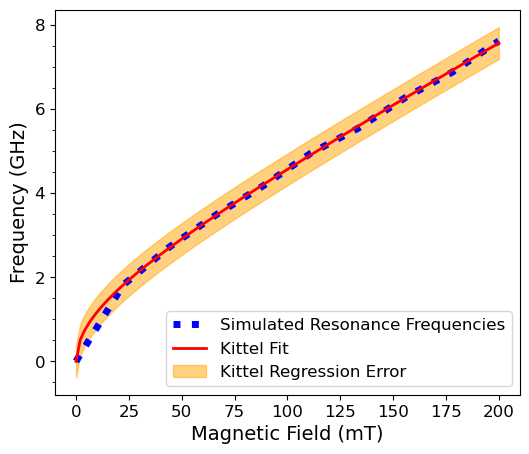

: 

In [ ]:
fig, ax = plt.subplots(figsize=(6,5))

def kittel(B, gamma_over_2pi, M_eff):
    '''Kittel formula for in-plane magnetisation'''

    mu_0 = 1.2566e-6     # N/A^2

    return (gamma_over_2pi)*np.sqrt(B*(B + mu_0*M_eff))

kittel_val, popt, perr = kittel_fit()

# df_kittel["Freq"] = df_kittel["Freq"].sort_values(ignore_index=True)
# df_kittel["Field"] = df_kittel["Field"].sort_values(ignore_index=True)

df_kittel = pd.DataFrame()

df_kittel['Field'] = np.linspace(0,fields.max(), 100)
df_kittel['Freq'] = kittel(df_kittel['Field'].values, *popt)


# kittel

# df_kittel = pd.DataFrame({'field':fields,
#                           'freq':kittel})

# print(df_kittel)

idx = np.argsort(fields)

x_sorted = fields[idx]
y_sorted = resFreqs[idx]

ax.plot(x_sorted*1e3, y_sorted/1e9,color='blue' ,ls = ':', linewidth = 5, alpha = 1,label='Simulated Resonance Frequencies')
# ax.scatter(fields*1e3, kittel/1e9)
ax.plot(df_kittel['Field']*1e3, df_kittel['Freq']/1e9,'r-', label='Kittel Fit', linewidth = 2)

ax.fill_between(df_kittel['Field']*1e3, (df_kittel['Freq'] - perr[0])/1e9, (df_kittel['Freq'] + perr[0])/1e9, color='orange', alpha=0.5, label='Kittel Regression Error')


ax.legend(fontsize = 12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
ml = MultipleLocator(2)
m2 = MultipleLocator(0.5)

ax.yaxis.set_major_locator(ml)
ax.yaxis.set_minor_locator(m2)
ax.set_xlabel("Magnetic Field (mT)", fontsize = 14)
ax.set_ylabel("Frequency (GHz)", fontsize = 14)

FOLDER_PATH = "C:\\Users\\nicoe\\OneDrive - Imperial College London\\Documents\\A Univeristy\\Year 4\\Masters Project\\Results\\Experiments\\Simulations\\mumax\\"

# save_path = f'{FOLDER_PATH}plots\\mumax_permalloy_kittel.svg'
# save_path = f'{FOLDER_PATH}plots\\mumax_yig_kittel.svg'

save_path = None

if save_path is not None:
    save_path = Path(save_path)

    try:
        save_path.parent.mkdir(parents=True, exist_ok=True)
    except Exception as e:
        print(f"Error creating directories for {save_path.parent}: {e}")
        

    fig.savefig(
        save_path,
        format=save_path.suffix.replace(".", ""),  # pdf, svg, eps
        dpi=300,
        bbox_inches="tight"
    )

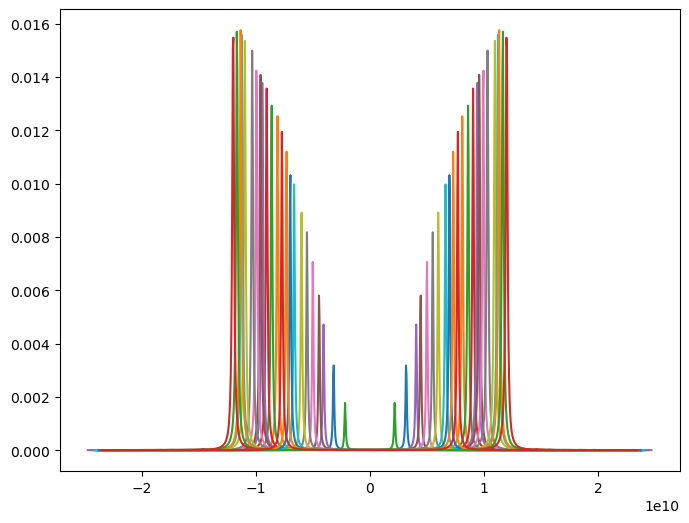

In [4]:
fig, ax = plt.subplots(figsize = (8,6))


for i, freqlist in enumerate(frequencies):
    ax.plot(freqlist, intensities[i])

[0.       0.1043   0.113    0.1217   0.1304   0.1391   0.1478   0.1565
 0.1652   0.1739   0.01739  0.1826   0.1913   0.2      0.02609  0.03478
 0.04348  0.05217  0.06087  0.06957  0.07826  0.08696  0.008696 0.09565 ]
[[0.       0.       0.       ... 0.       0.       0.      ]
 [0.1043   0.1043   0.1043   ... 0.1043   0.1043   0.1043  ]
 [0.113    0.113    0.113    ... 0.113    0.113    0.113   ]
 ...
 [0.08696  0.08696  0.08696  ... 0.08696  0.08696  0.08696 ]
 [0.008696 0.008696 0.008696 ... 0.008696 0.008696 0.008696]
 [0.09565  0.09565  0.09565  ... 0.09565  0.09565  0.09565 ]]


C:\Users\nicoe\AppData\Local\Temp\ipykernel_10876\809056569.py:21: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  plt.pcolormesh(freq_padded, field_padded, int_padded, shading='auto', cmap='viridis')


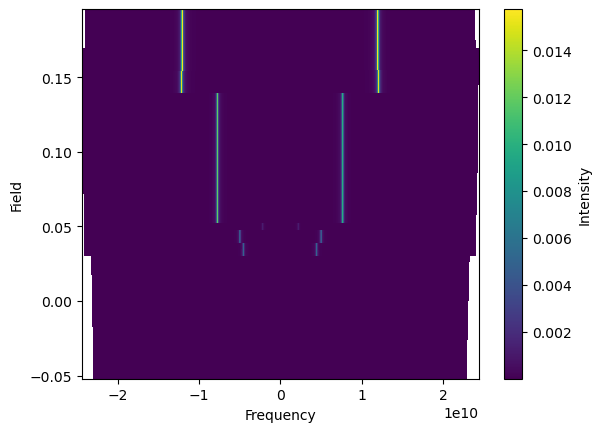

In [5]:


max_len = max(len(f) for f in frequencies)
n_rows = len(frequencies)

# Create padded arrays
freq_padded = np.full((n_rows, max_len), np.nan)
int_padded = np.full((n_rows, max_len), np.nan)
field_padded = np.full((n_rows, max_len), np.nan)

for i, (f, inten, field) in enumerate(zip(frequencies, intensities, fields)):
    length = len(f)
    freq_padded[i, :length] = f
    int_padded[i, :length] = inten
    field_padded[i, :length] = field  # repeat field value across the row


print(fields)

print(field_padded)

# Plot
plt.pcolormesh(freq_padded, field_padded, int_padded, shading='auto', cmap='viridis')
plt.xlabel("Frequency")
plt.ylabel("Field")
plt.colorbar(label="Intensity")
plt.show()

TypeError: colorbar() missing 1 required positional argument: 'mappable'

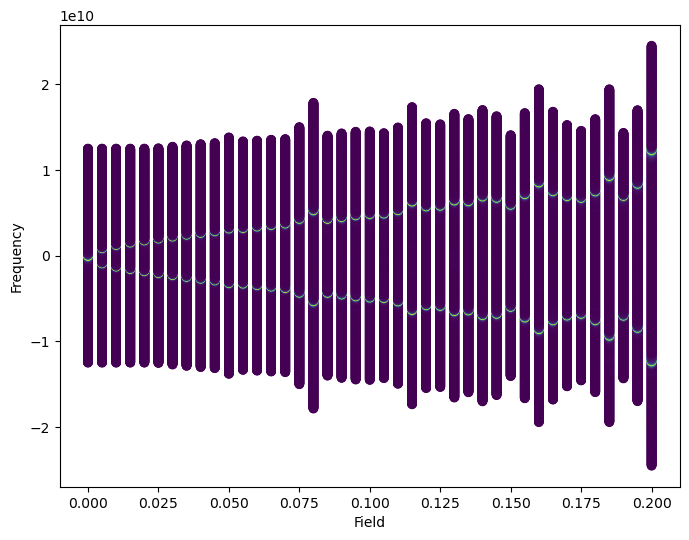

In [40]:
fig, ax = plt.subplots(figsize=(8,6))


freq_all = np.concatenate(frequencies)
int_all = np.concatenate(intensities)
field_all = np.concatenate([
    np.full(len(f), field) for f, field in zip(frequencies, fields)
])

ax.scatter(field_all, freq_all, c=int_all, cmap='viridis')
ax.set_ylabel("Frequency")
ax.set_xlabel("Field")
fig.colorbar(c=int_all, ax=ax, label="Intensity")

ax.set_xlim(-1.5e10, 1.5e10)



1024
(1024,)


ValueError: x and y must be the same size

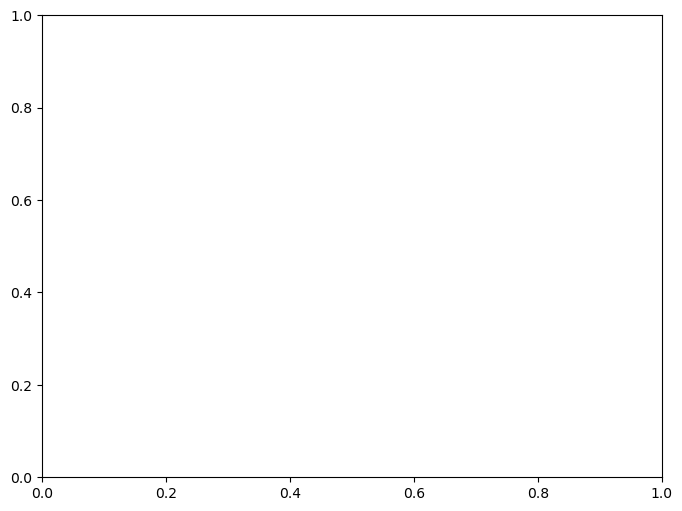

In [38]:
fig, ax = plt.subplots(figsize = (8,6))

for i, (f, int) in enumerate(zip(frequencies, intensities)):
    field = [int for i in range(len(f))]
    print(len(field))
    print(f.shape)
    ax.scatter(field, f[0], c=int, cmap='viridis')

(41984, 41)
(41984, 41)


TypeError: Dimensions of C (41, 2, 1024) should be one smaller than X(41) and Y(41984) while using shading='flat' see help(pcolormesh)

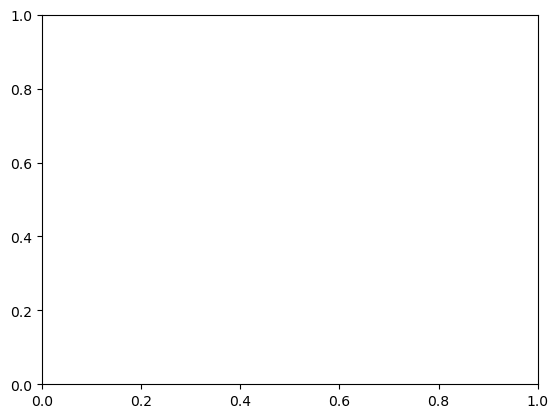

In [ ]:
xlabel = frequencies
ylabel = fields


y, x = np.meshgrid(ylabel, xlabel)
print(x.shape)
print(y.shape)
# print(calibrated_data.values.shape)
# print(calibrated_data.values)

fig, ax = plt.subplots()

max_val = 1
# max_val = 0.2

min_val = 0
# min_val = -0.3


# df4 = cal_plot_data2.copy()

# df4 = df4.div(df4.max(), axis = 0)


c = ax.pcolormesh(y*1000, x/1e9, list(zip(frequencies, intensities)), cmap='viridis', vmin=min_val, vmax=max_val)
# set the limits of the plot to the limits of the data
# ax.axis([0, 200, x.min()/1e9, 8])



data_label = f'$(S21^{{FMR}}-S21^{{ref}})/S21^{{ref}}$'
data_label = f'Intensity (A.U)'

fig.colorbar(c, ax=ax, label = f'{data_label}').set_label(label=f'{data_label}',size=14)


ml = MultipleLocator(2)
ax.yaxis.set_major_locator(ml)
plt.yticks(fontsize=12)
plt.xticks(fontsize=12)


ax.set_ylabel('Frequency (GHz)', fontsize = 14)
ax.set_xlabel('Magnetic Field (mT)', fontsize = 14)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
